## 0. Setup Awal

In [1]:
import os
import time
import tracemalloc
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings('ignore')

plt.style.use(
    'seaborn-v0_8-whitegrid'
    if 'seaborn-v0_8-whitegrid' in plt.style.available
    else 'default'
)

plt.rcParams['figure.dpi'] = 120

OUTPUT_DIR = 'outputLogisticRegressionL1AntiBurnout'
os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

## 1. Data Understanding

### 1.1 Load Dataset

In [2]:
df = pd.read_csv('burnout_dataset1.csv')

print(f'Jumlah data awal: {len(df)}')

df = df.sample(
    n=5000,
    random_state=42
).reset_index(drop=True)
print(f'Jumlah data setelah sampling: {len(df)}')

Jumlah data awal: 50000
Jumlah data setelah sampling: 5000


### 1.2 Identifikasi Kolom yang Digunakan

In [3]:
numeric_columns = df.select_dtypes(
    include='number'
).columns

categorical_columns = df.select_dtypes(
    include=['object', 'category']
).columns

print('Kolom Numerik:')
print(
    numeric_columns.tolist()
)

print(
    '\nKolom Kategorikal:'
)
print(
    categorical_columns.tolist()
)

Kolom Numerik:
['Person_ID', 'Age', 'Monthly_Income_USD', 'Work_Hours_Per_Week', 'Job_Satisfaction', 'Work_Life_Balance', 'Sleep_Hours', 'Anxiety_Score', 'Depression_Score', 'Mood_Score', 'Emotional_Stability', 'Physical_Activity_Hours', 'Meditation_Minutes', 'Screen_Time_Hours', 'Social_Media_Hours', 'Gaming_Hours', 'Coffee_Cups_Per_Day', 'Life_Satisfaction', 'Productivity_Score', 'Absenteeism_Days', 'Burnout_Score']

Kolom Kategorikal:
['Gender', 'Country', 'Occupation', 'Education_Level', 'Employment_Status', 'Remote_Work', 'Sleep_Quality', 'Stress_Level', 'Exercise_Frequency', 'Alcohol_Consumption', 'Smoking', 'Healthy_Diet', 'Chronic_Stress', 'Family_History_Mental_Illness', 'Therapy_Attendance', 'Support_System', 'Mental_Health_Status', 'AI_Wellness_Recommendation', 'Burnout_Risk']


## 2. Preprocessing

### 2.1 Seleksi Kolom

In [4]:
y = df['Burnout_Risk'].copy()

numeric_columns = numeric_columns.drop(
    ['Person_ID', 'Burnout_Score'],
    errors='ignore'
)

categorical_columns = categorical_columns.drop(
    [
        'Gender',
        'Country',
        'Occupation',
        'AI_Wellness_Recommendation',
        'Burnout_Risk',
        'Education_Level',
        'Employment_Status'
    ],
    errors='ignore'
)

selected_columns = (
    list(numeric_columns)
    + list(categorical_columns)
)

X = df[
    selected_columns
].copy()

X.head()

,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Mental_Health_Status
0,19.0,NaN,58,8.0,9.0,9.6,56.0,35.0,54.0,37,...,Moderate,Never,Yes,No,No,No,No,No,Poor,Needs Attention
1,48.0,NaN,53,1.0,8.0,4.7,36.0,NaN,60.0,60,...,Moderate,Never,No,Yes,No,No,Yes,No,Excellent,Needs Attention
2,42.0,NaN,59,3.0,2.0,4.9,44.0,62.0,53.0,49,...,Moderate,Daily,No,Yes,No,No,No,No,Average,Needs Attention
3,22.0,NaN,49,9.0,8.0,6.3,72.0,65.0,29.0,35,...,High,Never,No,Yes,Yes,Yes,No,Yes,Average,Needs Attention
4,62.0,NaN,39,3.0,9.0,4.3,45.0,52.0,69.0,56,...,Moderate,Weekly,No,Yes,No,No,Yes,No,Poor,Needs Attention


### 2.2 Encoding Data Kategorikal

In [5]:
encoding_maps = {
    'Remote_Work': {
        'No': 0,
        'Hybrid': 1,
        'Yes': 2
    },

    'Sleep_Quality': {
        'Excellent': 0,
        'Good': 1,
        'Average': 2,
        'Poor': 3
    },

    'Stress_Level': {
        'Low': 0,
        'Moderate': 1,
        'High': 2
    },

    'Exercise_Frequency': {
        'Daily': 0,
        'Weekly': 1,
        'Rarely': 2,
        'Never': 3
    },

    'Alcohol_Consumption': {
        'No': 0,
        'Yes': 1
    },

    'Smoking': {
        'No': 0,
        'Yes': 1
    },

    'Healthy_Diet': {
        'No': 1,
        'Yes': 0
    },

    'Chronic_Stress': {
        'No': 0,
        'Yes': 1
    },

    'Family_History_Mental_Illness': {
        'No': 0,
        'Yes': 1
    },

    'Therapy_Attendance': {
        'No': 1,
        'Yes': 0
    },

    'Support_System': {
        'Poor': 3,
        'Average': 2,
        'Good': 1,
        'Excellent': 0
    },

    'Mental_Health_Status': {
        'Healthy': 0,
        'Needs Attention': 1,
        'Critical': 2
    }
}

for column, mapping in encoding_maps.items():

    X[column] = (
        X[column]
        .map(mapping)
    )

target_mapping = {
    'Low': 0,
    'Moderate': 1,
    'High': 2
}

y = y.map(target_mapping)

X[categorical_columns].head()

,Remote_Work,Sleep_Quality,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Mental_Health_Status
0,1,0,1,3,1,0,1,0,0,1.0,3,1
1,2,3,1,3,0,1,1,0,1,1.0,0,1
2,0,3,1,0,0,1,1,0,0,1.0,2,1
3,2,2,2,3,0,1,0,1,0,0.0,2,1
4,2,3,1,1,0,1,1,0,1,1.0,3,1


### 2.3 Penanganan Missing Values

In [6]:
print(
    'Missing value sebelum preprocessing:'
)

print(
    X.isnull().sum()
)

print(
    '\nJumlah missing value:'
)
print(X.isnull().sum().sum())

Missing value sebelum preprocessing:
Age                                28
Monthly_Income_USD               1450
Work_Hours_Per_Week                 0
Job_Satisfaction                   37
Work_Life_Balance                  60
Sleep_Hours                        85
Anxiety_Score                      80
Depression_Score                   73
Mood_Score                         91
Emotional_Stability                 0
Physical_Activity_Hours           100
Meditation_Minutes                122
Screen_Time_Hours                  84
Social_Media_Hours                 62
Gaming_Hours                       69
Coffee_Cups_Per_Day                 0
Life_Satisfaction                  75
Productivity_Score                 80
Absenteeism_Days                    0
Remote_Work                         0
Sleep_Quality                       0
Stress_Level                        0
Exercise_Frequency                  0
Alcohol_Consumption                 0
Smoking                             0
Healthy_Diet 

### 2.4 Penanganan Outlier

### 2.5 Standardisasi

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train.shape, X_test.shape

((4000, 31), (1000, 31))

### 2.6 Data Bersih

In [8]:
print('Dimensi data fitur (X):', X.shape)
print('Dimensi data latih (X_train):', X_train.shape)
print('Dimensi data uji (X_test):', X_test.shape)
print('Jumlah missing value:', X.isnull().sum().sum())
print('\nDistribusi kelas target (y):')
print(y.value_counts())

X.head()

Dimensi data fitur (X): (5000, 31)
Dimensi data latih (X_train): (4000, 31)
Dimensi data uji (X_test): (1000, 31)
Jumlah missing value: 2539

Distribusi kelas target (y):
Burnout_Risk
0    2481
1    1512
2    1007
Name: count, dtype: int64


,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Mental_Health_Status
0,19.0,NaN,58,8.0,9.0,9.6,56.0,35.0,54.0,37,...,1,3,1,0,1,0,0,1.0,3,1
1,48.0,NaN,53,1.0,8.0,4.7,36.0,NaN,60.0,60,...,1,3,0,1,1,0,1,1.0,0,1
2,42.0,NaN,59,3.0,2.0,4.9,44.0,62.0,53.0,49,...,1,0,0,1,1,0,0,1.0,2,1
3,22.0,NaN,49,9.0,8.0,6.3,72.0,65.0,29.0,35,...,2,3,0,1,0,1,0,0.0,2,1
4,62.0,NaN,39,3.0,9.0,4.3,45.0,52.0,69.0,56,...,1,1,0,1,1,0,1,1.0,3,1


## 3. Modeling

### 3.1 Inisialisasi Model Logistic Regression L1

In [9]:
pipeline = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(
            penalty='l1',
            solver='saga',
            max_iter=10000,
            tol=1e-4,
            random_state=42
        ))
    ]
)

param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100]
}

### 3.2 Eksekusi Model dan Pengukuran Komputasi

In [10]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring={
        'accuracy': 'accuracy',
        'precision_macro': 'precision_macro',
        'recall_macro': 'recall_macro',
        'f1_macro': 'f1_macro',
        'f1_weighted': 'f1_weighted'
    },
    cv=cv,
    n_jobs=-1,
    refit='f1_macro',
    return_train_score=True
)

tracemalloc.start()
start_time = time.process_time()

search.fit(
    X_train,
    y_train
)

train_time = time.process_time() - start_time
current, peak = tracemalloc.get_traced_memory()
tracemalloc.stop()

train_memory_mb = peak / (1024 * 1024)
model = search.best_estimator_

print('Parameter terbaik:', search.best_params_)
print(f'F1 Macro Cross-Validation Terbaik: {search.best_score_:.4f}')
print(f'Waktu Eksekusi Training: {train_time:.4f} detik')
print(f'Penggunaan Memori Peak: {train_memory_mb:.4f} MB')

Parameter terbaik: {'classifier__C': 0.01}
F1 Macro Cross-Validation Terbaik: 0.9799
Waktu Eksekusi Training: 0.7031 detik
Penggunaan Memori Peak: 4.6107 MB


### 3.3 Prediksi Data Uji

In [11]:
y_pred = model.predict(
    X_test
)

df_prediksi = pd.DataFrame(
    {
        'Actual': y_test,
        'Predicted': y_pred
    },
    index=X_test.index
)

df_prediksi.head()

,Actual,Predicted
761,1,1
4863,0,0
3651,0,0
361,1,1
3197,0,0


## 4. Evaluasi

### 4.1 Laporan Klasifikasi (Classification Report)

In [12]:
target_names = ['Low (0)', 'Moderate (1)', 'High (2)']

report = classification_report(
    y_test,
    y_pred,
    target_names=target_names,
    digits=4,
    zero_division=0
)

print(report)

              precision    recall  f1-score   support

     Low (0)     1.0000    1.0000    1.0000       496
Moderate (1)     1.0000    0.9637    0.9815       303
    High (2)     0.9481    1.0000    0.9734       201

    accuracy                         0.9890      1000
   macro avg     0.9827    0.9879    0.9850      1000
weighted avg     0.9896    0.9890    0.9890      1000



### 4.2 Matriks Kebingungan (Confusion Matrix)

In [13]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print(cm)

[[496   0   0]
 [  0 292  11]
 [  0   0 201]]


### 4.3 Metrik Evaluasi Data Uji

In [14]:
acc = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec_macro = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1_macro = f1_score(y_test, y_pred, average='macro', zero_division=0)
f1_weighted = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print(f'Accuracy           : {acc:.4f}')
print(f'Precision (Macro)  : {prec_macro:.4f}')
print(f'Recall (Macro)     : {rec_macro:.4f}')
print(f'F1-Score (Macro)   : {f1_macro:.4f}')
print(f'F1-Score (Weighted): {f1_weighted:.4f}')

Accuracy           : 0.9890
Precision (Macro)  : 0.9827
Recall (Macro)     : 0.9879
F1-Score (Macro)   : 0.9850
F1-Score (Weighted): 0.9890


### 4.4 Evaluasi Stratified 5-Fold Cross-Validation

In [15]:
cv_results = search.cv_results_
best_index = search.best_index_

cv_metric_names = {
    'Accuracy': 'accuracy',
    'Precision (Macro)': 'precision_macro',
    'Recall (Macro)': 'recall_macro',
    'F1-Score (Macro)': 'f1_macro',
    'F1-Score (Weighted)': 'f1_weighted'
}

cv_rows = []
for fold in range(5):
    row = {'Fold': f'Fold {fold + 1}'}
    for metric_name, scorer_name in cv_metric_names.items():
        key = f'split{fold}_test_{scorer_name}'
        if key in cv_results:
            row[metric_name] = cv_results[key][best_index]
    cv_rows.append(row)

df_cv = pd.DataFrame(cv_rows)
df_cv.loc['Mean'] = ['Mean'] + [df_cv[col].mean() for col in df_cv.columns[1:]]
df_cv.loc['Std'] = ['Std'] + [df_cv[col].std() for col in df_cv.columns[1:]]
df_cv

,Fold,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),F1-Score (Weighted)
0,Fold 1,0.98875,0.982353,0.987603,0.984621,0.988796
1,Fold 2,0.99000,0.984221,0.988981,0.986317,0.990037
2,Fold 3,0.98125,0.971591,0.979339,0.974502,0.981367
3,Fold 4,0.98750,0.980507,0.986226,0.982927,0.987556
4,Fold 5,0.97875,0.968343,0.976487,0.971196,0.978891
Mean,Mean,0.98525,0.977403,0.983727,0.979913,0.985330
Std,Std,0.00443,0.006269,0.004910,0.005959,0.004388


### 4.5 Ringkasan Waktu Eksekusi dan Penggunaan Memori

In [16]:
df_runtime = pd.DataFrame(
    [
        {
            'Model': 'Logistic Regression L1',
            'Training_Time_Seconds': round(train_time, 4),
            'Peak_Memory_MB': round(train_memory_mb, 4)
        }
    ]
)

df_runtime

,Model,Training_Time_Seconds,Peak_Memory_MB
0,Logistic Regression L1,0.7031,4.6107


### 4.6 Ringkasan Evaluasi Model

In [17]:
best_params = search.best_params_

penalty_label = 'l1'
l1_ratio_value = np.nan
C_value = best_params['classifier__C']

if 'classifier__l1_ratio' in best_params:
    l1_ratio_value = best_params['classifier__l1_ratio']

evaluation_result = pd.DataFrame(
    {
        'Model': ['Logistic Regression L1'],
        'Penalty': [penalty_label],
        'L1_Ratio': [l1_ratio_value],
        'C': [C_value],
        'Accuracy': [round(acc, 4)],
        'Precision_Macro': [round(prec_macro, 4)],
        'Recall_Macro': [round(rec_macro, 4)],
        'F1_Score_Macro': [round(f1_macro, 4)],
        'F1_Score_Weighted': [round(f1_weighted, 4)],
        'CV_5Fold_Accuracy_Mean': [round(search.cv_results_['mean_test_accuracy'][search.best_index_], 4)],
        'CV_5Fold_F1_Macro_Mean': [round(search.best_score_, 4)],
        'Training_Time_s': [round(train_time, 4)],
        'Peak_Memory_MB': [round(train_memory_mb, 4)]
    }
)

evaluation_result

,Model,Penalty,L1_Ratio,C,Accuracy,Precision_Macro,Recall_Macro,F1_Score_Macro,F1_Score_Weighted,CV_5Fold_Accuracy_Mean,CV_5Fold_F1_Macro_Mean,Training_Time_s,Peak_Memory_MB
0,Logistic Regression L1,l1,NaN,0.01,0.989,0.9827,0.9879,0.985,0.989,0.9852,0.9799,0.7031,4.6107


## 5. Visualisasi Hasil

### 5.1 Visualisasi Confusion Matrix Heatmap

In [18]:
### 5.1 Visualisasi Confusion Matrix Heatmap

### 5.2 Visualisasi Distribusi Kelas Prediksi vs Aktual

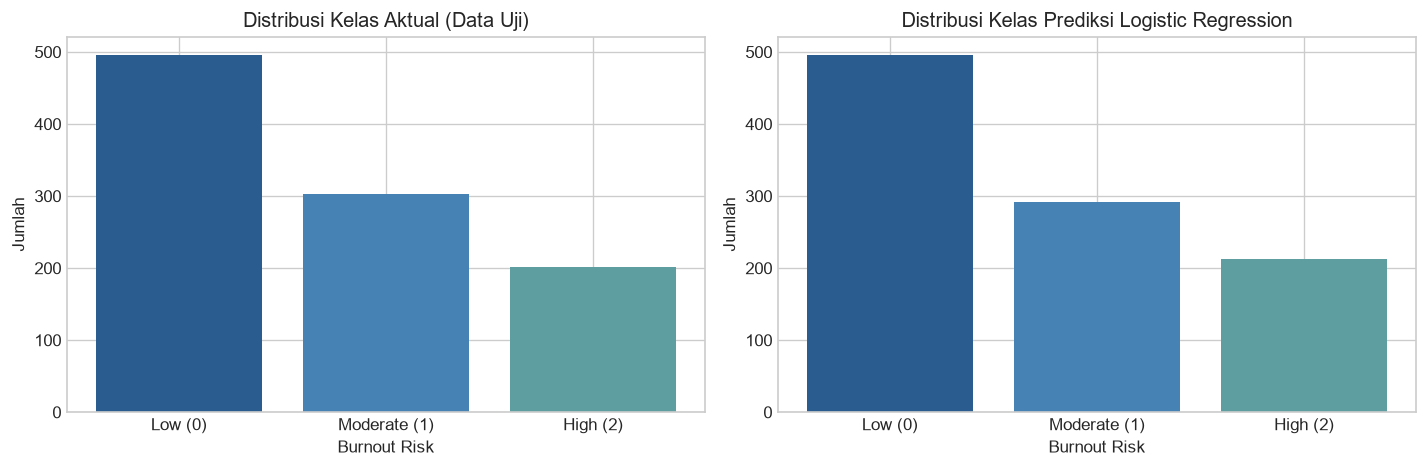

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

actual_counts = y_test.value_counts().reindex([0, 1, 2], fill_value=0)
predicted_counts = pd.Series(y_pred).value_counts().reindex([0, 1, 2], fill_value=0)

axes[0].bar(target_names, actual_counts.values, color=['#2b5c8f', '#4682b4', '#5f9ea0'])
axes[0].set_title('Distribusi Kelas Aktual (Data Uji)')
axes[0].set_xlabel('Burnout Risk')
axes[0].set_ylabel('Jumlah')

axes[1].bar(target_names, predicted_counts.values, color=['#2b5c8f', '#4682b4', '#5f9ea0'])
axes[1].set_title('Distribusi Kelas Prediksi Logistic Regression')
axes[1].set_xlabel('Burnout Risk')
axes[1].set_ylabel('Jumlah')

plt.tight_layout()
plt.savefig(
    f'{OUTPUT_DIR}/distribution_actual_vs_predicted_logistic_regression.png'
)
plt.show()

### 5.3 Visualisasi Metrik Evaluasi Stratified 5-Fold Cross-Validation

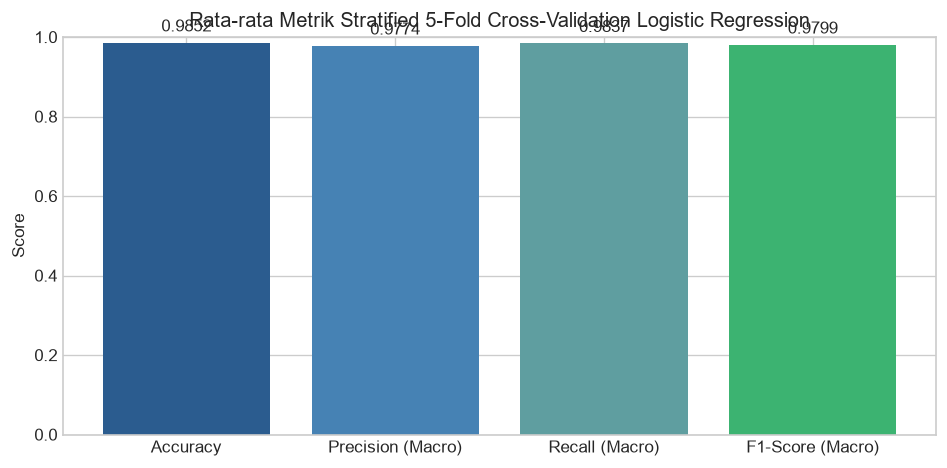

In [20]:
metrics_cv = ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1-Score (Macro)']
cv_means = [
    search.cv_results_['mean_test_accuracy'][search.best_index_],
    search.cv_results_['mean_test_precision_macro'][search.best_index_],
    search.cv_results_['mean_test_recall_macro'][search.best_index_],
    search.cv_results_['mean_test_f1_macro'][search.best_index_]
]

plt.figure(figsize=(8, 4))
bars = plt.bar(
    metrics_cv,
    cv_means,
    color=['#2b5c8f', '#4682b4', '#5f9ea0', '#3cb371']
)
plt.title('Rata-rata Metrik Stratified 5-Fold Cross-Validation Logistic Regression')
plt.ylabel('Score')
plt.ylim(0, 1)

for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 0.02,
        f'{yval:.4f}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.savefig(
    f'{OUTPUT_DIR}/cv_metrics_logistic_regression.png'
)
plt.show()

## 6. Analisis

### 6.1 Analisis Koefisien Fitur Model Logistic Regression

In [21]:
classifier = model.named_steps['classifier']

feature_names = X.columns.tolist()
class_names = [f'Class_{name}' for name in target_names]

df_coef = pd.DataFrame(
    classifier.coef_,
    columns=feature_names,
    index=class_names
)

df_coef.T.head(10)

,Class_Low (0),Class_Moderate (1),Class_High (2)
Age,0.0,0.0,0.0
Monthly_Income_USD,0.0,0.0,0.0
Work_Hours_Per_Week,0.0,0.0,0.0
Job_Satisfaction,0.0,0.0,0.0
Work_Life_Balance,0.0,0.0,0.0
Sleep_Hours,0.0,0.0,0.0
Anxiety_Score,0.0,0.0,0.0
Depression_Score,0.0,0.0,0.0
Mood_Score,0.0,0.0,0.0
Emotional_Stability,0.0,0.0,0.0


### 6.2 Visualisasi 10 Fitur Terpenting Berdasarkan Nilai Koefisien Absolut

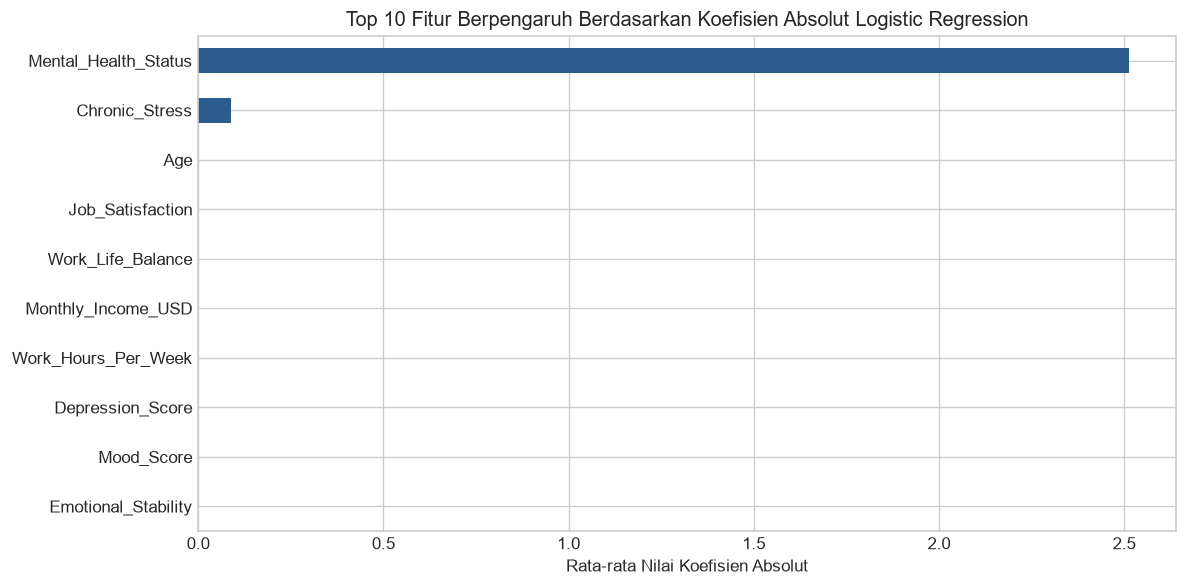

In [22]:
top_features = np.abs(classifier.coef_).mean(axis=0)
top_features_series = pd.Series(
    top_features,
    index=X.columns
).sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
top_features_series.plot(
    kind='barh',
    color='#2b5c8f'
)
plt.title('Top 10 Fitur Berpengaruh Berdasarkan Koefisien Absolut Logistic Regression')
plt.xlabel('Rata-rata Nilai Koefisien Absolut')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(
    f'{OUTPUT_DIR}/top_features_logistic_regression.png'
)
plt.show()

## 7. Ekspor File

### 7.1 Ekspor Ringkasan Evaluasi

In [23]:
evaluation_result.to_csv(
    f'{OUTPUT_DIR}/metrics_logistic_regression_l1.csv',
    index=False
)

### 7.2 Ekspor Hasil Prediksi Data Uji

In [24]:
df_prediksi.to_csv(
    f'{OUTPUT_DIR}/predictions_logistic_regression_l1.csv'
)

### 7.3 Ekspor Hasil 5-Fold Cross-Validation

In [25]:
df_cv.to_csv(
    f'{OUTPUT_DIR}/cv_5fold_logistic_regression_l1.csv',
    index=False
)